# Chapter 5 · Vector Data & Classical NLP: Full-Length BBC News, `vkvec` GPU Search & Chunking

In Chapters 1–2 we worked with **Tabular data** (rows and columns of numbers). In Chapters 3–4 we worked with **Image data** (2D grids of pixels). Now we tackle the third pillar of modern AI: **Vector / Text Data & Natural Language Processing (`NLP`)**.

### What Is NLP (Natural Language Processing) in Plain English?
Computers can't read English words directly — a GPU only understands floating-point numbers. Every `NLP` system follows the same 3-step pipeline:
1. **`Tokenization`:** Clean and split raw text into tokens (words or subwords) and drop common filler words like `the`, `and`, `said`.
2. **Vectorization (`BoW`, `TF-IDF`, or Neural `Embedding`):** Turn each document into a point (a **vector** of numbers) in high-dimensional space.
3. **Meaning & Geometry (`Cosine Similarity`):** Once text is a vector, **similarity becomes geometry**! Two articles about the same topic point in almost the same direction (`score → 1.0`), while unrelated articles point at 90° (`score → 0.0`).

### Our Real-World Dataset: Full-Length BBC News (2,225 Complete Articles)
Instead of tiny 1-sentence snippets, we will work with **2,225 full, multi-paragraph BBC News articles** (median **337 words**, up to **4,492 words**!) across 5 real sections: **`Business`**, **`Entertainment`**, **`Politics`**, **`Sport`**, and **`Tech`**.

In this chapter we use our bundled **`vkvec`** Vulkan GPU vector toolkit to:
- Inspect real full-length articles & split them leak-free (`1,780` train / `445` test)
- Turn articles into L2-normalized **2,000-D `TF-IDF` vectors** on Vulkan GPU (`vkvec.TfidfVectorizer`)
- Build an in-VRAM **GPU Vector Database** (`vkvec.VectorIndex`) with **metadata filtering (`where=`)** and **RAG passage chunking (`vkvec.chunk_text`)**
- Map all 2,225 articles into a 2D neon topic galaxy with **`vkvis.UMAP`**
- Race 4 Classical NLP models on GPU (**`93.26%` → `97.30%`**) — and discover the **Synonym Wall** that sets up Chapter 6!

In [1]:
import csv, sys, time, urllib.request
from pathlib import Path
import numpy as np
from IPython.display import display

for p in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
    if (p / "vknumpy").is_dir() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

import vknumpy as vnp
import vkpandas as vpd
import vklearn as vkl
import vkvis
import vkvec

print(f"Vulkan GPU ready: {vnp.device_info()['name']}")

# Download & cache the 2,225 full-length BBC News articles
DATA_DIR = Path("data/bbc_news")
DATA_DIR.mkdir(parents=True, exist_ok=True)
CSV_PATH = DATA_DIR / "bbc-text.csv"
if not CSV_PATH.exists():
    fallback = Path("data/bbc-text.csv")
    if fallback.exists():
        CSV_PATH.write_bytes(fallback.read_bytes())
    else:
        url = "https://raw.githubusercontent.com/susanli2016/PyCon-Canada-2019-NLP-Tutorial/master/bbc-text.csv"
        print("Downloading Full-Length BBC News CSV...")
        urllib.request.urlretrieve(url, CSV_PATH)

CLASS_NAMES = ["Business", "Entertainment", "Politics", "Sport", "Tech"]
PALETTE = ["#36f9f6", "#ff7edb", "#fede5d", "#72f1b8", "#ff9e64"]
cat2id = {c.lower(): i for i, c in enumerate(CLASS_NAMES)}

df = vpd.read_csv(CSV_PATH)
display(df.head(5))
display(df.describe())

# Reproducible 80/20 shuffle split (exact same split used in Chapter 6!)
all_texts  = df["text"].to_list()
all_labels = np.array([cat2id[c] for c in df["category"].to_list()], dtype=np.int32)
texts_tr, texts_te, y_tr, y_te = vkl.train_test_split(all_texts, all_labels, test_size=0.2, random_state=42)

word_counts = [len(t.split()) for t in all_texts]
print(f"Loaded {len(all_texts):,} full-length BBC articles ({len(texts_tr):,} train / {len(texts_te):,} test)")
print(f"Article length (words): median={int(np.median(word_counts))}, mean={np.mean(word_counts):.0f}, max={max(word_counts):,}\n")
for cid, cname in enumerate(CLASS_NAMES):
    sample = next(t for t, y in zip(texts_tr, y_tr) if y == cid)
    print(f"  [{cname:13s}] ({len(sample.split()):3d} words) {sample[:100]}...")


Vulkan GPU ready: AMD Custom GPU 0405 (RADV VANGOGH)


ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


#,category,text
0,tech,tv future in the hands of viewers with home t...
1,business,worldcom boss left books alone former world...
2,sport,tigers wary of farrell gamble leicester say...
3,sport,yeading face newcastle in fa cup premiership ...
4,entertainment,ocean s twelve raids box office ocean s twelv...


'vkpandas.DataFrame (2,225 rows x 2 columns)\n  category | CATEGORICAL (5 unique): sport(511), business(510), politics(417), tech(401), entertainment(386)\n  text     | CATEGORICAL (2126 unique): ocean s twelve raids box office ocean s twelve  the crime caper sequel starring george clooney  brad pitt and julia roberts  has gone straight to number one in the us box office chart.  it took $40.8m (£21m) in weekend ticket sales  according to studio estimates. the sequel follows the master criminals as they try to pull off three major heists across europe. it knocked last week s number one  national treasure  into third place. wesley snipes  blade: trinity was in second  taking $16.1m (£8.4m). rounding out the top five was animated fable the polar express  starring tom hanks  and festive comedy christmas with the kranks.  ocean s twelve box office triumph marks the fourth-biggest opening for a december release in the us  after the three films in the lord of the rings trilogy. the sequel narrowly beat its 2001 predecessor  ocean s eleven which took $38.1m (£19.8m) on its opening weekend and $184m (£95.8m) in total. a remake of the 1960s film  starring frank sinatra and the rat pack  ocean s eleven was directed by oscar-winning director steven soderbergh. soderbergh returns to direct the hit sequel which reunites clooney  pitt and roberts with matt damon  andy garcia and elliott gould. catherine zeta-jones joins the all-star cast.  it s just a fun  good holiday movie   said dan fellman  president of distribution at warner bros. however  us critics were less complimentary about the $110m (£57.2m) project  with the los angeles times labelling it a  dispiriting vanity project . a milder review in the new york times dubbed the sequel  unabashedly trivial .(2), hague  given up  his pm ambition former conservative leader william hague says he will not stand for the leadership again  having given up his ambition to be prime minister.  mr hague  43  told the daily telegraph he would now find a life dominated by politics too  boring  and unfulfilling. mr hague  who stepped down after his party s 2001 election defeat  does not rule out a return to the front bench. he also told the paper he hopes to remain mp for richmond  north yorks  and start a family with wife ffion. mr hague  who recently had published the biography of william pitt the younger  also said he wanted to continue writing books and speech-writing.  he told the newspaper:  i don t know whether i will ever go back on to the front  but don t rush me.  asked if he would stand for the leadership again  mr hague replied:  no. definitely not.  his determination to stay away from a central role will disappoint some senior conservative members  who say the party needs him. tim collins  the shadow education secretary  said last week it would be a  huge boost  to the party if mr hague returned to the front bench. mr hague became an mp at 27 and leader of the opposition at 36. he said:  i feel fortunate that  by the age of 40  i had crammed in an entire political career.  i had been in the cabinet and been leader of the party  so now i can branch out into other things...it is a very liberating feeling.  mr hague added that he may have misjudged his own ambition to be prime minister.  maybe i wasn t as driven by politics as i thought i was   he said.(2), broadband in the uk growing fast high-speed net connections in the uk are proving more popular than ever.  bt reports that more people signed up for broadband in the last three months than in any other quarter. the 600 000 connections take the total number of people in the uk signing up for broadband from bt to almost 3.3 million. nationally more than 5 million browse the net via broadband. britain now has among the highest number of broadband connections throughout the whole of europe.  according to figures gathered by industry watchdog  ofcom  the growth means that the uk has now surpassed germany in terms of broadband users per 100 peopl

Loaded 2,225 full-length BBC articles (1,780 train / 445 test)
Article length (words): median=337, mean=390, max=4,492

  [Business     ] (609 words) saab to build cadillacs in sweden general motors  the world s largest car maker  has confirmed that ...
  [Entertainment] (1300 words) franz man seeks government help franz ferdinand frontman alex kapranos has called for more governmen...
  [Politics     ] (1212 words) what the election should really be about  a general election is the best chance most pressure groups...
  [Sport        ] (244 words) smith keen on home series return scotland manager walter smith has given his backing to the reinstat...
  [Tech         ] (395 words) microsoft debuts security tools microsoft is releasing tools that clean up pcs harbouring viruses an...


---
### Step 1 · Turning Full Articles into `TF-IDF` Vectors with `vkvec`

A naive `BoW` (Bag-of-Words) counter treats common words like *"said"*, *"government"*, or *"people"* the same as distinctive topic words like *"playstation"* or *"premiership"*. **`TF-IDF`** fixes this by boosting rare, topic-defining words and L2-normalizing every document vector to length `1.0` on your Vulkan GPU — so `Cosine Similarity` is literally a single GPU matrix multiply (`q @ X.T`)!

In [2]:
t0 = time.perf_counter()
vec = vkvec.TfidfVectorizer(max_features=2000, use_idf=True, sublinear_tf=True, l2_normalize=True)
X_tr = vec.fit_transform(texts_tr)   # (1780, 2000) L2-normalized in Vulkan VRAM
X_te = vec.transform(texts_te)       # (445,  2000) fitted strictly on train (zero leakage!)
dt_vec = time.perf_counter() - t0

print(f"Vectorized 2,225 full articles -> GPU shape {X_tr.shape} & {X_te.shape} in {dt_vec:.2f}s")

# Inspect the top 5 highest-IDF words for each BBC section
X_tr_np = X_tr.to_numpy()
print("\nTop distinctive TF-IDF words per BBC News section:")
for cid, cname in enumerate(CLASS_NAMES):
    mean_vec = X_tr_np[y_tr == cid].mean(axis=0)
    top_words = [vec.vocabulary_[i] for i in np.argsort(mean_vec)[-7:][::-1]]
    print(f"  {cname:13s} -> {', '.join(top_words)}")


Vectorized 2,225 full articles -> GPU shape (1780, 2000) & (445, 2000) in 0.58s

Top distinctive TF-IDF words per BBC News section:
  Business      -> market, company, firm, growth, shares, economy, bank
  Entertainment -> film, best, show, star, award, awards, music
  Politics      -> labour, government, election, party, blair, minister, people
  Sport         -> game, win, against, match, england, cup, team
  Tech          -> people, technology, users, software, computer, digital, use


---
### Step 2 · Vulkan GPU Vector Database (`vkvec.VectorIndex`) & Full-Article RAG Chunking (`vkvec.chunk_text`)

With full-length 400–4,000 word articles, real **`RAG`** (Retrieval-Augmented Generation) pipelines do two things:
1. **Article-level GPU Vector Search** (with optional **`where=` metadata filtering**, e.g. search only within `Tech` or `Business`).
2. **Passage Chunking (`vkvec.chunk_text`)** — slicing long articles into overlapping ~120-word passages so a search engine returns the *exact paragraph* that answers your question instead of dumping a 4,000-word article into an LLM!

In [3]:
# 1. Build an in-VRAM GPU Vector Database of all 1,780 training articles
article_index = vkvec.VectorIndex(metric="cosine").add(
    X_tr,
    metadata=[{"topic": CLASS_NAMES[y], "words": len(t.split()), "text": t} for y, t in zip(y_tr, texts_tr)],
)

def show_search(query, k=3, where=None):
    t0 = time.perf_counter()
    hits = article_index.search(vec.transform([query]), k=k, where=where)[0]
    ms = (time.perf_counter() - t0) * 1000.0
    filt = f"  [where={where}]" if where else ""
    print(f"Query: {query!r}{filt}  ({ms:.2f} ms on Vulkan GPU)")
    for rank, h in enumerate(hits, 1):
        m = h["metadata"]
        print(f"  #{rank}  cos={h['score']:.3f}  [{m['topic']:13s} | {m['words']:4d}w]  {m['text'][:92]}...")
    print()

show_search("broadband internet mobile phone gaming console")
show_search("stock market economy inflation interest rates", where={"topic": "Business"})

# 2. RAG Passage Chunking on the longest articles using vkvec.chunk_text!
chunk_texts, chunk_meta = [], []
for doc_id, (txt, y) in enumerate(zip(texts_tr[:300], y_tr[:300])):
    for ci, ch in enumerate(vkvec.chunk_text(txt, chunk_size=120, overlap=25)):
        chunk_texts.append(ch)
        chunk_meta.append({"doc_id": doc_id, "chunk": ci, "topic": CLASS_NAMES[y], "text": ch})

chunk_index = vkvec.VectorIndex(metric="cosine").add(vec.transform(chunk_texts), metadata=chunk_meta)
print(f"Chunked 300 full articles -> {len(chunk_index):,} overlapping 120-word RAG passages in Vulkan VRAM!")
rag_hit = chunk_index.search(vec.transform(["oscar academy award best film actor"]), k=1)[0][0]
print(f"Top RAG passage (cos={rag_hit['score']:.3f}, [{rag_hit['metadata']['topic']}], chunk #{rag_hit['metadata']['chunk']}):")
print(" ", rag_hit["metadata"]["text"][:220] + "...")


Query: 'broadband internet mobile phone gaming console'  (6.88 ms on Vulkan GPU)
  #1  cos=0.251  [Tech          |  261w]  moving mobile improves golf swing a mobile phone that recognises and responds to movements h...
  #2  cos=0.250  [Tech          |  217w]  broadband steams ahead in the us more and more americans are joining the internet s fast lan...
  #3  cos=0.246  [Tech          |  201w]  sony psp console hits us in march us gamers will be able to buy sony s playstation portable ...

Query: 'stock market economy inflation interest rates'  [where={'topic': 'Business'}]  (6.91 ms on Vulkan GPU)
  #1  cos=0.329  [Business      |  293w]  bank voted 8-1 for no rate change the decision to keep interest rates on hold at 4.75% earli...
  #2  cos=0.329  [Business      |  391w]  markets signal brazilian recovery the brazilian stock market has risen to a record high as i...
  #3  cos=0.327  [Business      |  460w]  bank opts to leave rates on hold the bank of england has left interest rate

---
### Step 3 · Visualizing 2,000-D Full-Article Vectors in 2D (`vkvis.UMAP`)

Can we actually *see* 2,000-dimensional text vectors? **`vkvis.UMAP`** projects all 1,780 full-length BBC articles down to 2D on your Vulkan GPU while preserving cosine neighborhoods — watch how cleanly the 5 news sections separate into glowing islands!

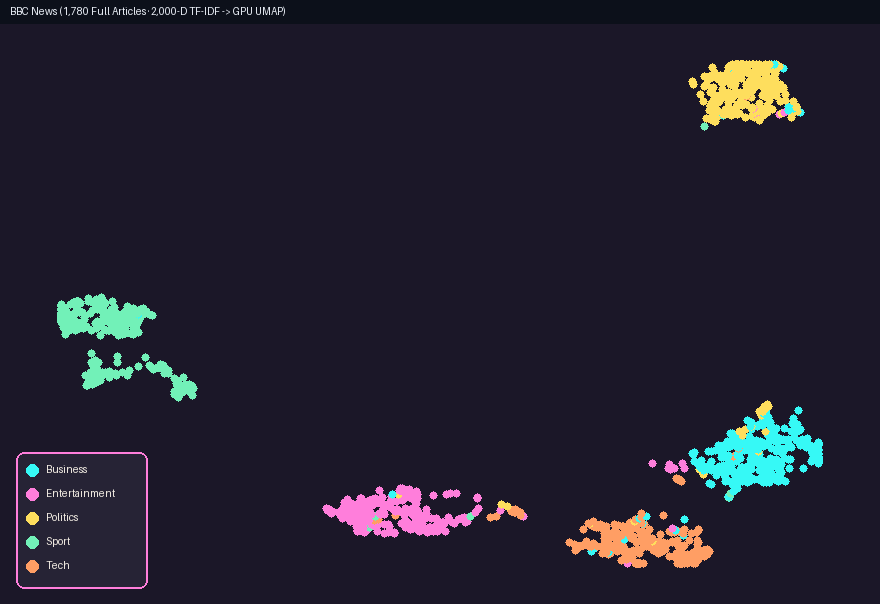

GPU UMAP completed in 4.32s


In [4]:
t0 = time.perf_counter()
Y_umap = vkvis.UMAP(n_neighbors=15, min_dist=0.15, n_epochs=250, metric="cosine", seed=42).fit_transform(X_tr_np)
dt_umap = time.perf_counter() - t0

display(vkvis.render_embedding(
    Y_umap, labels=y_tr, palette=PALETTE, class_names=CLASS_NAMES, legend_loc="lower left",
    clip_percentile=1.5, background="#1b1728", width=880, height=580, point_size=4,
    title="BBC News (1,780 Full Articles · 2,000-D TF-IDF -> GPU UMAP)",
))
print(f"GPU UMAP completed in {dt_umap:.2f}s")


---
### Step 4 · Classical NLP Classification Race (`vklearn` on Vulkan GPU)

Now let's benchmark 4 Classical NLP pipelines on the exact 445 held-out test articles:
1. **Bag-of-Words (`BoW`, 2,000-D) + GPU `KNN`** (baseline — raw word counts)
2. **`TF-IDF` (2,000-D) + GPU `KNN`** (does IDF weighting beat raw counts?)
3. **`TF-IDF` → GPU `PCA` (64-D) + One-vs-Rest `Ridge`** (compressing 2,000-D down to 64-D)
4. **`TF-IDF` (2,000-D) + One-vs-Rest GPU `Ridge`** (linear hyperplane per news section)

In [5]:
def ovr_ridge_predict(Xtr_gpu, ytr_np, Xte_gpu, alpha=1.5):
    scores = np.zeros((Xte_gpu.shape[0], len(CLASS_NAMES)), dtype=np.float32)
    for c in range(len(CLASS_NAMES)):
        yc = (ytr_np == c).astype(np.float32)
        scores[:, c] = vkl.Ridge(alpha=alpha).fit(Xtr_gpu, yc).predict(Xte_gpu).to_numpy()
    return np.argmax(scores, axis=1)

# 1. Bag-of-Words + GPU KNN
t0 = time.perf_counter()
bow = vkvec.TfidfVectorizer(max_features=2000, use_idf=False, sublinear_tf=False)
Xb_tr, Xb_te = bow.fit_transform(texts_tr), bow.transform(texts_te)
pred_bow = vkl.KNeighborsClassifier(n_neighbors=11).fit(Xb_tr, y_tr).predict(Xb_te).to_numpy()
dt_bow, acc_bow = time.perf_counter() - t0, float(vkl.accuracy_score(y_te, pred_bow))

# 2. TF-IDF + GPU KNN
t0 = time.perf_counter()
pred_knn = vkl.KNeighborsClassifier(n_neighbors=11).fit(X_tr, y_tr).predict(X_te).to_numpy()
dt_knn, acc_knn = time.perf_counter() - t0, float(vkl.accuracy_score(y_te, pred_knn))

# 3. TF-IDF -> GPU PCA (64-D) + OvR Ridge
t0 = time.perf_counter()
pca = vkl.PCA(n_components=64).fit(X_tr)
Z_tr, Z_te = pca.transform(X_tr), pca.transform(X_te)
pred_pca = ovr_ridge_predict(Z_tr, y_tr, Z_te, alpha=1.0)
dt_pca, acc_pca = time.perf_counter() - t0, float(vkl.accuracy_score(y_te, pred_pca))

# 4. TF-IDF (2000-D) + OvR GPU Ridge
t0 = time.perf_counter()
pred_ridge = ovr_ridge_predict(X_tr, y_tr, X_te, alpha=1.5)
dt_ridge, acc_ridge = time.perf_counter() - t0, float(vkl.accuracy_score(y_te, pred_ridge))

print(f"{'Classical NLP Model (BBC News 445 Test Articles)':46s} | {'Test Acc':>8s} | {'Time':>6s}")
print("-" * 68)
for name, acc, dt in [
    ("1. Bag-of-Words (2000-D) + GPU KNN",      acc_bow,   dt_bow),
    ("2. TF-IDF (2000-D) + GPU KNN",            acc_knn,   dt_knn),
    ("3. TF-IDF -> PCA (64-D) + GPU Ridge",     acc_pca,   dt_pca),
    ("4. TF-IDF (2000-D) + GPU Ridge (Winner)", acc_ridge, dt_ridge),
]:
    print(f"{name:46s} | {acc*100:7.2f}% | {dt:5.2f}s")


Classical NLP Model (BBC News 445 Test Articles) | Test Acc |   Time
--------------------------------------------------------------------
1. Bag-of-Words (2000-D) + GPU KNN             |   93.26% |  0.63s
2. TF-IDF (2000-D) + GPU KNN                   |   95.28% |  0.02s
3. TF-IDF -> PCA (64-D) + GPU Ridge            |   96.40% |  3.40s
4. TF-IDF (2000-D) + GPU Ridge (Winner)        |   97.30% |  1.58s


---
### Step 5 · Hitting the Classic **Synonym Wall** (Why Deep NLP Needs Learned Embeddings)

`TF-IDF` got an impressive **`97.30%`** on long BBC articles where topics repeat lots of overlapping keywords. **So why did modern AI switch to neural embeddings?**

Watch what happens when two short queries mean the **exact same thing** using **different words** (zero shared vocabulary):

In [6]:
pairs = [
    ("laptop computer software chip",         "internet broadband microsoft security"),
    ("stock market economy bank profit",      "shares inflation investor growth"),
    ("football striker match coach goal",     "rugby olympic tournament champion"),
    ("movie cinema actor director oscar",     "music album singer concert award"),
]
print("TF-IDF Cosine Similarity on zero-word-overlap synonym pairs:")
for a, b in pairs:
    va, vb = vec.transform([a]), vec.transform([b])
    sim = float(vkvec.cosine_similarity(va, vb).to_numpy()[0, 0])
    print(f"  sim = {sim:+.3f}  |  '{a}'  <->  '{b}'")
print("\nEvery single synonym pair scores 0.000! In Chapter 6, we train a vktorch Neural Text Encoder to shatter this wall.")


TF-IDF Cosine Similarity on zero-word-overlap synonym pairs:
  sim = +0.000  |  'laptop computer software chip'  <->  'internet broadband microsoft security'
  sim = +0.000  |  'stock market economy bank profit'  <->  'shares inflation investor growth'
  sim = +0.000  |  'football striker match coach goal'  <->  'rugby olympic tournament champion'
  sim = +0.000  |  'movie cinema actor director oscar'  <->  'music album singer concert award'

Every single synonym pair scores 0.000! In Chapter 6, we train a vktorch Neural Text Encoder to shatter this wall.
